In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

In [12]:
def segmentar(img, bloco=101, c=-10, area_min=500, invertir=False):
    suave = cv2.GaussianBlur(img, (5, 5), 0)
    tipo = cv2.THRESH_BINARY_INV if invertir else cv2.THRESH_BINARY
    adapt = cv2.adaptiveThreshold(suave, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                  tipo, bloco, c)

    contornos, _ = cv2.findContours(adapt, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contornos = [k for k in contornos if cv2.contourArea(k) > area_min]

    # Semântica: uma única classe (objeto = 255, fundo = 0)
    semantica = np.zeros(img.shape, np.uint8)
    cv2.drawContours(semantica, contornos, -1, 255, -1)

    # Instância: cada contorno recebe um ID próprio (1, 2, 3, ...)
    instancia = np.zeros(img.shape, np.int32)
    for i, k in enumerate(contornos):
        cv2.drawContours(instancia, [k], -1, i + 1, -1)

    return semantica, instancia, len(contornos)


def colorir(instancia):
    n = instancia.max()
    saida = np.zeros((*instancia.shape, 3), np.uint8)
    cores = plt.get_cmap('nipy_spectral')(np.linspace(0.1, 0.95, max(n, 1)))[:, :3]
    cores = cores[np.random.default_rng(0).permutation(n)]
    for i in range(n):
        saida[instancia == i + 1] = (cores[i] * 255).astype(np.uint8)
    return saida


def comparar(img, **kw):
    sem, inst, n = segmentar(img, **kw)
    plt.figure(figsize=(15, 4))
    for i, (im, t) in enumerate([(img, 'Entrada'),
                                 (sem, 'Semântica (1 classe: objeto)'),
                                 (colorir(inst), f'Instância (1 cor por objeto): {n}')]):
        plt.subplot(1, 3, i + 1)
        plt.imshow(im, cmap='gray')
        plt.title(t)
        plt.axis('off')
    plt.show()
    return n

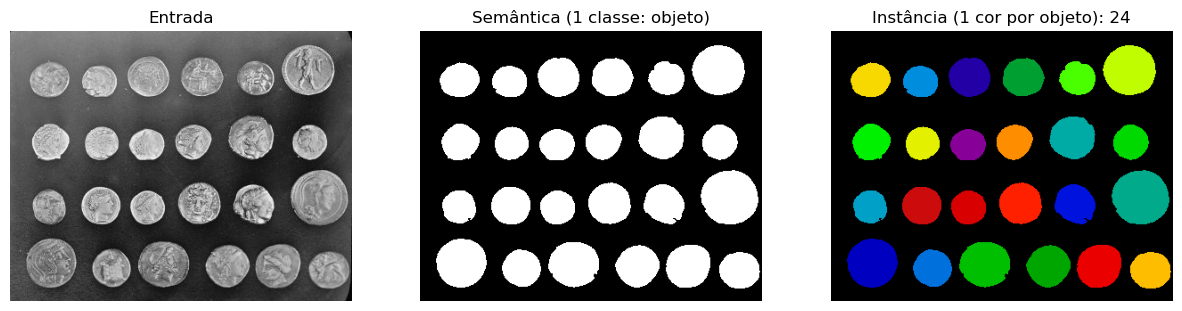

In [13]:
n_moedas = comparar(data.coins())

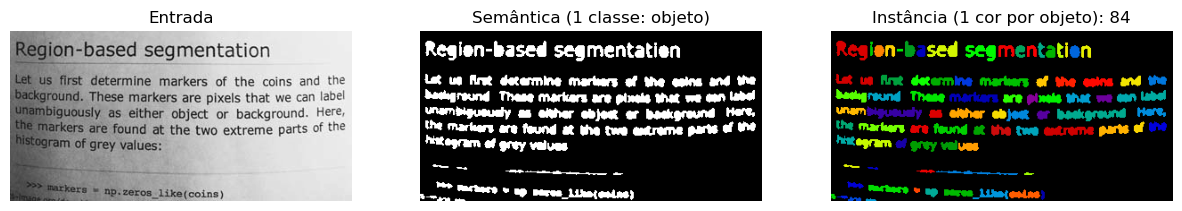

In [14]:
n_texto = comparar(data.page(), bloco=41, c=8, area_min=8, invertir=True)